# Testing multiple machine learning approaches.

## Load packages

https://auto.gluon.ai/0.4.0/tutorials/tabular_prediction/tabular-quickstart.html

In [ ]:
%pip install autogluon

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of statsforecast to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of fasttransform to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of python-fasthtml to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of python-fasthtml to determine which version is com

In [ ]:
from autogluon.tabular import TabularDataset, TabularPredictor
import pandas as pd
import numpy as np

Connect to drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


Load the datasets

In [ ]:
data = TabularDataset('/content/drive/Shareddrives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/extract_embeddings/OutputAlphaEarthEmbeddings/AE_3y_embeddings.csv')

#subsample_size = 500  # subsample subset of data for faster demo, try setting this to much larger values
#train_data = train_data.sample(n=subsample_size, random_state=0)
data.head()

,Unnamed: 0,id,class,lon,lat,inventory_year,A00_2,A00_1,A00_0,A01_2,...,A60_0,A61_2,A61_1,A61_0,A62_2,A62_1,A62_0,A63_2,A63_1,A63_0
0,1,0,F1_2,2.945650,50.829231,2019,-0.113741,-0.103406,-0.103406,-0.186082,...,-0.022207,-0.084214,-0.098424,-0.084214,-0.119093,-0.055363,-0.103406,-0.071111,-0.066990,-0.038447
1,2,1,F1_2,2.946892,50.829040,2019,-0.135886,-0.108512,-0.130165,-0.147697,...,-0.002215,-0.075356,-0.103406,-0.075356,-0.048228,-0.000984,-0.038447,-0.088827,-0.160000,-0.075356
2,3,2,F1_2,2.948197,50.828701,2019,-0.186082,-0.130165,-0.172795,-0.160000,...,-0.015748,-0.103406,-0.103406,-0.113741,0.017778,0.027128,0.004983,-0.103406,-0.103406,-0.066990
3,4,3,F1_2,2.948436,50.828369,2019,-0.251965,-0.221453,-0.228897,-0.135886,...,-0.003937,-0.166336,-0.166336,-0.172795,0.088827,0.113741,0.088827,0.008858,0.019931,0.027128
4,5,4,F1_2,2.947491,50.828123,2019,-0.228897,-0.199862,-0.214133,-0.130165,...,-0.019931,-0.153787,-0.141730,-0.147697,0.119093,0.147697,0.098424,0.007443,0.008858,0.017778


In [ ]:
type(data)

pandas.core.frame.DataFrame

In [ ]:
test_data = data.loc[data['inventory_year'] == 2021]
train_data = data.loc[data['inventory_year'] != 2021]


test_data = test_data.drop(columns=['id','Unnamed: 0','lon','lat','inventory_year'])

train_data = train_data.drop(columns=['id','Unnamed: 0','lon','lat','inventory_year'])
train_data.head()


,class,A00_2,A00_1,A00_0,A01_2,A01_1,A01_0,A02_2,A02_1,A02_0,...,A60_0,A61_2,A61_1,A61_0,A62_2,A62_1,A62_0,A63_2,A63_1,A63_0
0,F1_2,-0.113741,-0.103406,-0.103406,-0.186082,-0.172795,-0.172795,-0.172795,-0.093564,-0.147697,...,-0.022207,-0.084214,-0.098424,-0.084214,-0.119093,-0.055363,-0.103406,-0.071111,-0.066990,-0.038447
1,F1_2,-0.135886,-0.108512,-0.130165,-0.147697,-0.147697,-0.153787,-0.172795,-0.130165,-0.179377,...,-0.002215,-0.075356,-0.103406,-0.075356,-0.048228,-0.000984,-0.038447,-0.088827,-0.160000,-0.075356
2,F1_2,-0.186082,-0.130165,-0.172795,-0.160000,-0.147697,-0.153787,-0.186082,-0.147697,-0.214133,...,-0.015748,-0.103406,-0.103406,-0.113741,0.017778,0.027128,0.004983,-0.103406,-0.103406,-0.066990
3,F1_2,-0.251965,-0.221453,-0.228897,-0.135886,-0.098424,-0.103406,-0.284444,-0.244152,-0.276140,...,-0.003937,-0.166336,-0.166336,-0.172795,0.088827,0.113741,0.088827,0.008858,0.019931,0.027128
4,F1_2,-0.228897,-0.199862,-0.214133,-0.130165,-0.093564,-0.103406,-0.236463,-0.186082,-0.244152,...,-0.019931,-0.153787,-0.141730,-0.147697,0.119093,0.147697,0.098424,0.007443,0.008858,0.017778


In [ ]:
test_data.head()

,class,A00_2,A00_1,A00_0,A01_2,A01_1,A01_0,A02_2,A02_1,A02_0,...,A60_0,A61_2,A61_1,A61_0,A62_2,A62_1,A62_0,A63_2,A63_1,A63_0
18314,F1_2,-0.214133,-0.206936,-0.214133,-0.103406,-0.079723,-0.048228,-0.179377,-0.124567,-0.147697,...,-0.048228,-0.113741,-0.135886,-0.172795,0.001538,-0.044844,-0.048228,-0.051734,-0.055363,0.003937
18315,F1_2,-0.199862,-0.199862,-0.221453,-0.206936,-0.206936,-0.221453,-0.179377,-0.206936,-0.147697,...,0.130165,-0.088827,-0.093564,-0.079723,-0.048228,-0.027128,-0.007443,-0.124567,-0.124567,-0.147697
18316,F1_2,-0.199862,-0.192910,-0.179377,-0.244152,-0.251965,-0.221453,-0.214133,-0.206936,-0.166336,...,0.103406,-0.135886,-0.113741,-0.135886,-0.029773,-0.044844,-0.029773,-0.088827,-0.103406,-0.059116
18317,F1_2,-0.206936,-0.206936,-0.221453,-0.292872,-0.301423,-0.310096,-0.199862,-0.192910,-0.172795,...,0.130165,-0.084214,-0.093564,-0.093564,-0.012057,-0.015748,0.041584,-0.153787,-0.147697,-0.130165
18318,F1_2,-0.192910,-0.179377,-0.221453,-0.199862,-0.206936,-0.147697,-0.179377,-0.119093,-0.160000,...,0.024606,-0.124567,-0.098424,-0.147697,-0.071111,-0.062991,-0.084214,-0.119093,-0.135886,-0.079723


In [ ]:
label = 'class'
print("Summary of class variable: \n", train_data[label].describe())

Summary of class variable: 
 count     24604
unique        6
top          F3
freq       7234
Name: class, dtype: object


<Axes: xlabel='class', ylabel='count'>

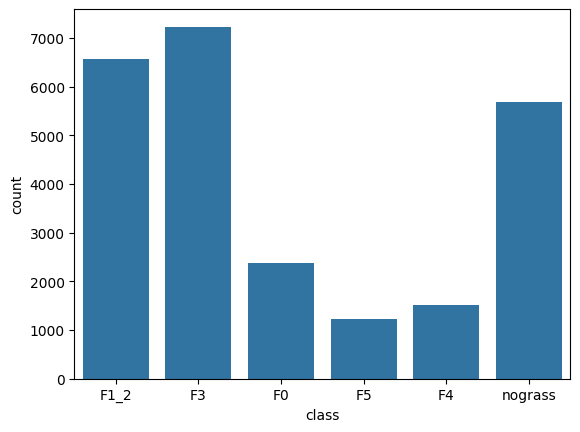

In [ ]:
import seaborn as sns
sns.countplot(x=train_data[label])

In [ ]:
print(len(train_data))
train_data = train_data.dropna()
print(len(train_data))

24604
24604


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


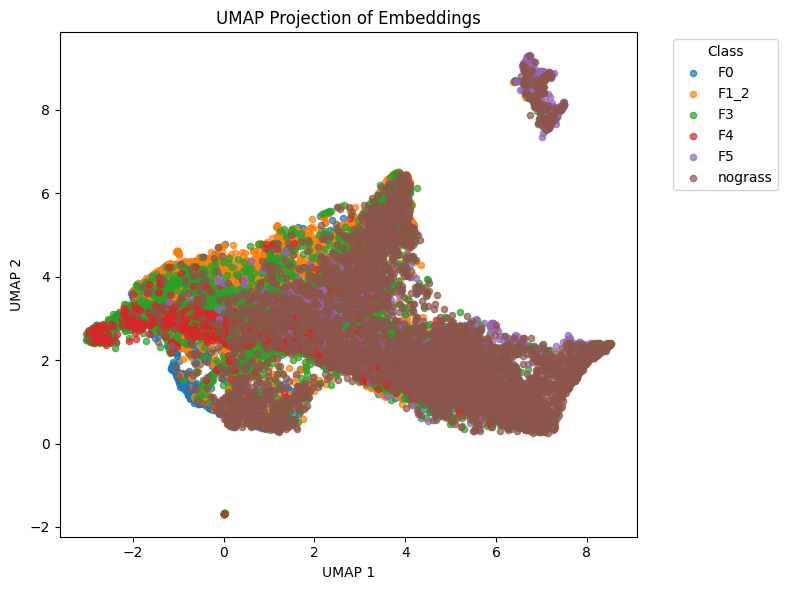

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from umap import UMAP

# Split labels and embeddings
# The 'class' column contains the labels, and the rest are embeddings
labels = train_data['class']
embeddings = train_data.drop(columns=['class']).values

# Run UMAP
umap = UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

embedding_2d = umap.fit_transform(embeddings)

# Create a DataFrame for plotting
plot_df = pd.DataFrame({
    "UMAP1": embedding_2d[:, 0],
    "UMAP2": embedding_2d[:, 1],
    "UMAP3": embedding_2d[:, 2],
    "Label": labels.values
})

# Plot
plt.figure(figsize=(8, 6))

for label in sorted(plot_df["Label"].unique()):
    subset = plot_df[plot_df["Label"] == label]
    plt.scatter(
        subset["UMAP1"],
        subset["UMAP2"],
        s=20,
        alpha=0.7,
        label=str(label)
    )

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP Projection of Embeddings")
plt.legend(title="Class", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

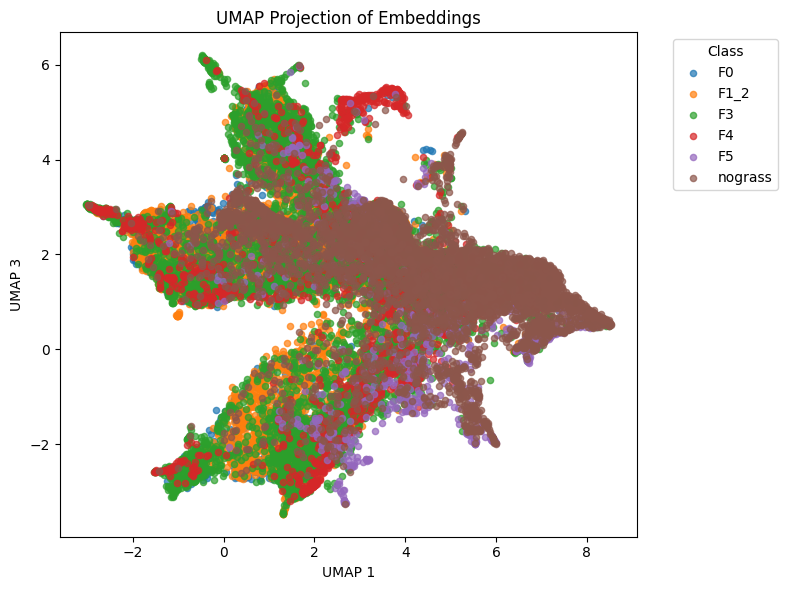

In [ ]:
plt.figure(figsize=(8, 6))

for label in sorted(plot_df["Label"].unique()):
    subset = plot_df[plot_df["Label"] == label]
    plt.scatter(
        subset["UMAP1"],
        subset["UMAP3"],
        s=20,
        alpha=0.7,
        label=str(label)
    )

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 3")
plt.title("UMAP Projection of Embeddings")
plt.legend(title="Class", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

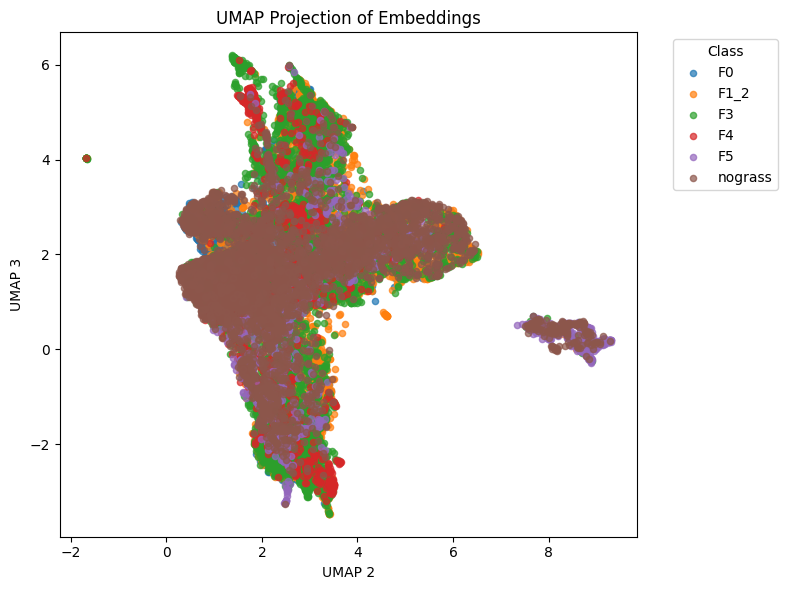

In [ ]:
plt.figure(figsize=(8, 6))

for label in sorted(plot_df["Label"].unique()):
    subset = plot_df[plot_df["Label"] == label]
    plt.scatter(
        subset["UMAP2"],
        subset["UMAP3"],
        s=20,
        alpha=0.7,
        label=str(label)
    )

plt.xlabel("UMAP 2")
plt.ylabel("UMAP 3")
plt.title("UMAP Projection of Embeddings")
plt.legend(title="Class", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Naïve approach: not taking spatial autocorrelation into account.

In [ ]:
save_path = '/content/drive/Shareddrives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/extract_embeddings/AutoML_AlphaEarth_prediction_output_3yr/'  # specifies folder to store trained models
#predictor = TabularPredictor(label=label, path=save_path).fit(train_data,num_gpus=1)
label = 'class'
TabularPredictor(label=label, path=save_path,eval_metric='f1_macro').fit(train_data,calibrate_decision_threshold=True)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       10.22 GB / 12.67 GB (80.6%)
Disk Space Avail:   81.50 GB / 107.72 GB (75.7%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme'  : Use this if you have a GPU. The go-to preset for best results, and the one to use for benchmark comparisons. New in v1.6: far better than 'best' on datasets <100000 samples by using Tabular Foundation Models (TFMs) meta-learned on https://tabarena.ai: Nori, TabICLv2, an

[1000]	valid_set's multi_logloss: 0.969112	valid_set's f1_macro: 0.615726


	0.6195	 = Validation score   (f1_macro)
	102.34s	 = Training   runtime
	1.42s	 = Validation runtime
Fitting model: LightGBM ...
Specified total num_gpus: 1, but only 0 are available. Will use 0 instead
	Fitting with cpus=1, gpus=0, mem=0.4/10.1 GB
	0.6089	 = Validation score   (f1_macro)
	53.34s	 = Training   runtime
	0.33s	 = Validation runtime
Fitting model: RandomForestGini ...
Specified total num_gpus: 1, but only 0 are available. Will use 0 instead
	Fitting with cpus=2, gpus=0, mem=0.7/10.1 GB
	0.5749	 = Validation score   (f1_macro)
	45.1s	 = Training   runtime
	0.19s	 = Validation runtime
Fitting model: RandomForestEntr ...
Specified total num_gpus: 1, but only 0 are available. Will use 0 instead
	Fitting with cpus=2, gpus=0, mem=0.7/10.0 GB
	0.5712	 = Validation score   (f1_macro)
	55.16s	 = Training   runtime
	0.18s	 = Validation runtime
Fitting model: CatBoost ...
Specified total num_gpus: 1, but only 0 are available. Will use 0 instead
	Fitting with cpus=1, gpus=0
	0.6131	 

In [ ]:
label = 'class'
y_test = test_data[label]  # values to predict
test_data_nolab = test_data.drop(columns=[label])  # delete label column to prove we're not cheating
test_data_nolab.head()

,A00_2,A00_1,A00_0,A01_2,A01_1,A01_0,A02_2,A02_1,A02_0,A03_2,...,A60_0,A61_2,A61_1,A61_0,A62_2,A62_1,A62_0,A63_2,A63_1,A63_0
18314,-0.214133,-0.206936,-0.214133,-0.103406,-0.079723,-0.048228,-0.179377,-0.124567,-0.147697,-0.051734,...,-0.048228,-0.113741,-0.135886,-0.172795,0.001538,-0.044844,-0.048228,-0.051734,-0.055363,0.003937
18315,-0.199862,-0.199862,-0.221453,-0.206936,-0.206936,-0.221453,-0.179377,-0.206936,-0.147697,0.048228,...,0.130165,-0.088827,-0.093564,-0.079723,-0.048228,-0.027128,-0.007443,-0.124567,-0.124567,-0.147697
18316,-0.199862,-0.192910,-0.179377,-0.244152,-0.251965,-0.221453,-0.214133,-0.206936,-0.166336,0.108512,...,0.103406,-0.135886,-0.113741,-0.135886,-0.029773,-0.044844,-0.029773,-0.088827,-0.103406,-0.059116
18317,-0.206936,-0.206936,-0.221453,-0.292872,-0.301423,-0.310096,-0.199862,-0.192910,-0.172795,0.051734,...,0.130165,-0.084214,-0.093564,-0.093564,-0.012057,-0.015748,0.041584,-0.153787,-0.147697,-0.130165
18318,-0.192910,-0.179377,-0.221453,-0.199862,-0.206936,-0.147697,-0.179377,-0.119093,-0.160000,-0.055363,...,0.024606,-0.124567,-0.098424,-0.147697,-0.071111,-0.062991,-0.084214,-0.119093,-0.135886,-0.079723


In [ ]:
predictor = TabularPredictor.load(save_path)  # unnecessary, just demonstrates how to load previously-trained predictor from file

y_pred = predictor.predict(test_data_nolab)
print("Predictions:  \n", y_pred)
perf = predictor.evaluate_predictions(y_true=y_test, y_pred=y_pred, auxiliary_metrics=True)

Predictions:  
 18314    nograss
18315       F1_2
18316    nograss
18317       F1_2
18318       F1_2
          ...   
27027    nograss
27028    nograss
27029    nograss
27030         F3
27031    nograss
Name: class, Length: 8718, dtype: object


In [ ]:
perf

{'f1_macro': 0.4499002219079686,
 'accuracy': 0.5326909841706814,
 'balanced_accuracy': np.float64(0.44335328159216925),
 'mcc': np.float64(0.37945228309524776)}

In [ ]:
predictor.leaderboard(test_data, silent=True)

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI,0.484435,0.612756,f1_macro,0.235166,0.066611,27.013251,0.235166,0.066611,27.013251,1,True,1
1,CatBoost,0.460537,0.613101,f1_macro,0.293749,0.062294,1059.786613,0.293749,0.062294,1059.786613,1,True,6
2,WeightedEnsemble_L2,0.449900,0.643023,f1_macro,0.404125,0.095988,1169.852642,0.015196,0.003094,0.491075,2,True,12
3,RandomForestEntr,0.446913,0.571161,f1_macro,1.665596,0.176613,55.155098,1.665596,0.176613,55.155098,1,True,5
4,RandomForestGini,0.445093,0.574921,f1_macro,2.722296,0.194270,45.097591,2.722296,0.194270,45.097591,1,True,4
5,LightGBM,0.444895,0.608853,f1_macro,1.223119,0.332351,53.340881,1.223119,0.332351,53.340881,1,True,3
6,XGBoost,0.443263,0.610316,f1_macro,1.403961,0.324148,154.968008,1.403961,0.324148,154.968008,1,True,9
7,ExtraTreesEntr,0.437281,0.563272,f1_macro,2.344785,0.383387,25.454924,2.344785,0.383387,25.454924,1,True,8
8,ExtraTreesGini,0.435972,0.554819,f1_macro,1.682213,0.220958,16.786727,1.682213,0.220958,16.786727,1,True,7
9,LightGBMXT,0.434352,0.619538,f1_macro,8.414724,1.416568,102.337425,8.414724,1.416568,102.337425,1,True,2


Prediction probabilities instead of final classes.

In [ ]:
pred_probs = predictor.predict_proba(test_data_nolab)
pred_probs.head(5)

,F0,F1_2,F3,F4,F5,nograss
18314,0.005211,0.010054,0.004266,0.000055,0.000006,0.980408
18315,0.012614,0.885451,0.077159,0.000191,0.000242,0.024343
18316,0.015624,0.455774,0.063386,0.000300,0.000764,0.464153
18317,0.023636,0.681168,0.054627,0.000732,0.001627,0.238210
18318,0.022904,0.761569,0.103979,0.001166,0.000061,0.110322


In [ ]:
results = predictor.fit_summary(show_plot=True)

*** Summary of fit() ***
Estimated performance of each model:
                  model  score_val eval_metric  pred_time_val     fit_time  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0   WeightedEnsemble_L2   0.643023    f1_macro       0.095988  1169.852642                0.003094           0.491075            2       True         12
1        NeuralNetTorch   0.630254    f1_macro       0.030600   109.574954                0.030600         109.574954            1       True         10
2            LightGBMXT   0.619538    f1_macro       1.416568   102.337425                1.416568         102.337425            1       True          2
3              CatBoost   0.613101    f1_macro       0.062294  1059.786613                0.062294        1059.786613            1       True          6
4       NeuralNetFastAI   0.612756    f1_macro       0.066611    27.013251                0.066611          27.013251            1       True          1
5               XGBo

In [ ]:
print("AutoGluon infers problem type is: ", predictor.problem_type)
print("AutoGluon identified the following types of features:")
print(predictor.feature_metadata)

AutoGluon infers problem type is:  multiclass
AutoGluon identified the following types of features:
('float', []) : 192 | ['A00_2', 'A00_1', 'A00_0', 'A01_2', 'A01_1', ...]


In [ ]:
predictor.predict(test_data, model='LightGBM')

,class
18314,nograss
18315,F1_2
18316,F1_2
18317,F1_2
18318,F1_2
...,...
27027,nograss
27028,nograss
27029,nograss
27030,F3


## Maximising predictability

In [ ]:
time_limit = 120  # for quick demonstration only, you should set this to longest time you are willing to wait (in seconds)
metric = 'f1_macro'  # specify your evaluation metric here
predictor2 = TabularPredictor(label, eval_metric=metric).fit(train_data, time_limit=time_limit, presets='best_quality') # see 'best_quality', 'high_quality', 'good_quality' or 'medium_quality'
predictor2.leaderboard(test_data, silent=True)


No path specified. Models will be saved in: "AutogluonModels/ag-20261026_151010"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       7.55 GB / 12.67 GB (59.6%)
Disk Space Avail:   84.32 GB / 107.72 GB (78.3%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stack

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,LightGBMXT_BAG_L1,0.072625,0.095631,f1_macro,0.205708,0.074883,33.611814,0.205708,0.074883,33.611814,1,True,1
1,WeightedEnsemble_L3,0.072625,0.095631,f1_macro,0.208788,0.084585,33.632591,0.003081,0.009702,0.020777,3,True,3
2,WeightedEnsemble_L2,0.072625,0.095631,f1_macro,0.209532,0.087072,33.629775,0.003824,0.012189,0.017960,2,True,2


## Confusion matrix

['F0' 'F1_2' 'F3' 'F4' 'F5' 'nograss']
[[ 239  328  130   25    4   85]
 [ 115 1856  375   35   36  280]
 [  28  774  871  224   61  411]
 [   3   79  196  240    1   83]
 [   0   28    7    1   87  104]
 [  49  262  151   11   33 1506]]


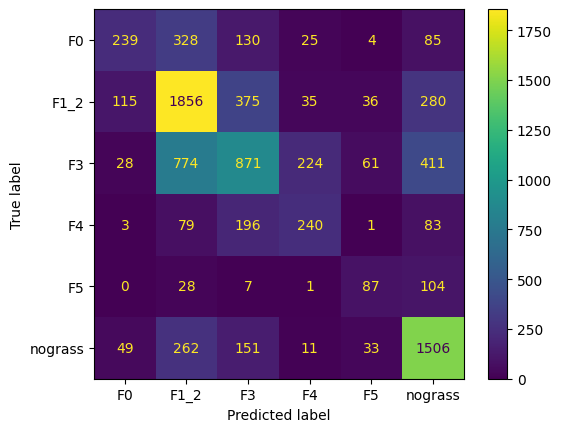

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
#pred = predictor2.predict(test_data, model='NeuralNetFastAI_BAG_L1')
#pred2 = predictor2.predict(test_data)
pred = predictor.predict(test_data, model='NeuralNetFastAI')

cm = confusion_matrix(y_test, pred)

labels_used = np.unique(np.concatenate([y_test, pred]))
print(labels_used)


print(cm)
cm_display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = labels_used)

cm_display.plot()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

# --- Predictions ---
pred = predictor.predict(test_data, model='LightGBMXT')

# Keep labels sorted and consistent across metrics
labels_used = np.unique(np.concatenate([y_test, pred]))

# --- 1. Compute per-class F1 scores ---
# Setting average=None returns an array containing the F1-score for each label in `labels`
f1_per_class = f1_score(y_test, pred, labels=labels_used, average=None)

# Optional: Print numerical breakdown
print(classification_report(y_test, pred, target_names=[str(l) for l in labels_used]))

# --- 2. Plotting F1 Scores & Confusion Matrix side-by-side ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Per-class F1 bar chart
bars = axes[0].bar([str(l) for l in labels_used], f1_per_class, color='steelblue', edgecolor='black', alpha=0.85)
axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel('Class', fontsize=11)
axes[0].set_ylabel('F1 Score', fontsize=11)
axes[0].set_title('Per-Class F1 Score', fontsize=13)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Display score values on top of each bar
for bar, score in zip(bars, f1_per_class):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.2f}",
        ha='center',
        va='bottom',
        fontsize=9
    )

# Right plot: Confusion Matrix
cm = confusion_matrix(y_test, pred, labels=labels_used)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_used)
cm_display.plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Confusion Matrix', fontsize=13)

plt.tight_layout()
plt.show()